In [1]:
import sys
sys.path.append("..")

import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import (StratifiedKFold, cross_validate, GridSearchCV,
                                     RandomizedSearchCV, cross_val_predict)
from sklearn.metrics import (precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, confusion_matrix, classification_report)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from src.preprocessing import get_preprocessor

train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

X_train, y_train = train.drop(columns=["Churn"]), train["Churn"]
X_test, y_test = test.drop(columns=["Churn"]), test["Churn"]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


In [2]:
candidates = {
    "Plain": Pipeline([
        ("preprocess", get_preprocessor(X_train)),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "Class weights": Pipeline([
        ("preprocess", get_preprocessor(X_train)),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
    ]),
    "SMOTE": ImbPipeline([
        ("preprocess", get_preprocessor(X_train)),
        ("smote", SMOTE(random_state=42)),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
}

scoring = ["roc_auc", "recall", "precision", "f1"]

rows = {}
for name, pipe in candidates.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows[name] = {m: res[f"test_{m}"].mean() for m in scoring}

pd.DataFrame(rows).T.round(3)

/Users/sonuu/Desktop/telco-churn/.venv/lib/python3.9/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
/Users/sonuu/Desktop/telco-churn/.venv/lib/python3.9/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
/Users/sonuu/Desktop/telco-churn/.venv/lib/python3.9/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
/Users/son

,roc_auc,recall,precision,f1
Plain,0.846,0.543,0.654,0.593
Class weights,0.846,0.803,0.518,0.629
SMOTE,0.845,0.792,0.525,0.631


In [3]:
lr_pipe = Pipeline([
    ("preprocess", get_preprocessor(X_train)),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)),
])

lr_search = GridSearchCV(
    lr_pipe,
    param_grid={"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    scoring="roc_auc", cv=cv, n_jobs=-1,
)
lr_search.fit(X_train, y_train)

print("Best params:", lr_search.best_params_)
print("Best CV ROC-AUC:", round(lr_search.best_score_, 4))

Best params: {'model__C': 10}
Best CV ROC-AUC: 0.8462


In [4]:
gb_pipe = Pipeline([
    ("preprocess", get_preprocessor(X_train)),
    ("model", HistGradientBoostingClassifier(class_weight="balanced", random_state=42)),
])

gb_params = {
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4, 5],
    "model__max_iter": [100, 200, 300],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0, 1, 5, 10],
}

gb_search = RandomizedSearchCV(
    gb_pipe, gb_params, n_iter=20,
    scoring="roc_auc", cv=cv, n_jobs=-1, random_state=42,
)
gb_search.fit(X_train, y_train)

print("Best params:", gb_search.best_params_)
print("Best CV ROC-AUC:", round(gb_search.best_score_, 4))

Best params: {'model__min_samples_leaf': 50, 'model__max_iter': 200, 'model__max_depth': 2, 'model__learning_rate': 0.1, 'model__l2_regularization': 5}
Best CV ROC-AUC: 0.8483


In [5]:
print("Logistic regression CV AUC:", round(lr_search.best_score_, 4))
print("Gradient boosting CV AUC:  ", round(gb_search.best_score_, 4))

if gb_search.best_score_ - lr_search.best_score_ > 0.005:
    best_name, best_model = "Gradient Boosting", gb_search.best_estimator_
else:
    best_name, best_model = "Logistic Regression", lr_search.best_estimator_

print("Chosen:", best_name)

Logistic regression CV AUC: 0.8462
Gradient boosting CV AUC:   0.8483
Chosen: Logistic Regression


Chosen threshold: 0.32


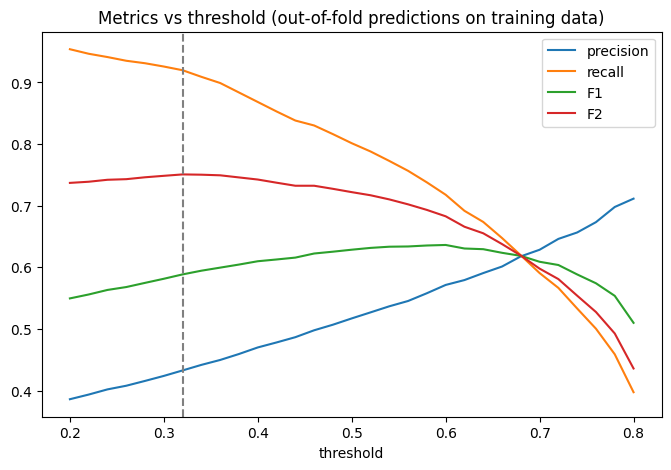

,precision,recall,F1,F2
threshold,,,,
0.30,0.424,0.926,0.581,0.748
0.40,0.470,0.868,0.610,0.742
0.50,0.517,0.801,0.629,0.722
0.32,0.433,0.920,0.588,0.751


In [6]:
oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv,
                              method="predict_proba", n_jobs=-1)[:, 1]

rows = []
for t in np.arange(0.20, 0.81, 0.02):
    p = (oof_proba >= t).astype(int)
    rows.append({
        "threshold": round(t, 2),
        "precision": precision_score(y_train, p),
        "recall": recall_score(y_train, p),
        "F1": f1_score(y_train, p),
        "F2": fbeta_score(y_train, p, beta=2),
    })

thr = pd.DataFrame(rows).set_index("threshold")
best_threshold = thr["F2"].idxmax()
print("Chosen threshold:", best_threshold)

thr[["precision", "recall", "F1", "F2"]].plot(figsize=(8, 5))
plt.axvline(best_threshold, color="grey", linestyle="--")
plt.title("Metrics vs threshold (out-of-fold predictions on training data)")
plt.show()

thr.loc[[0.3, 0.4, 0.5, best_threshold]].round(3)

Logistic Regression, threshold 0.32
ROC-AUC: 0.841
              precision    recall  f1-score   support

      Stayed       0.95      0.57      0.71      1035
     Churned       0.44      0.92      0.59       374

    accuracy                           0.67      1409
   macro avg       0.70      0.75      0.65      1409
weighted avg       0.82      0.67      0.68      1409



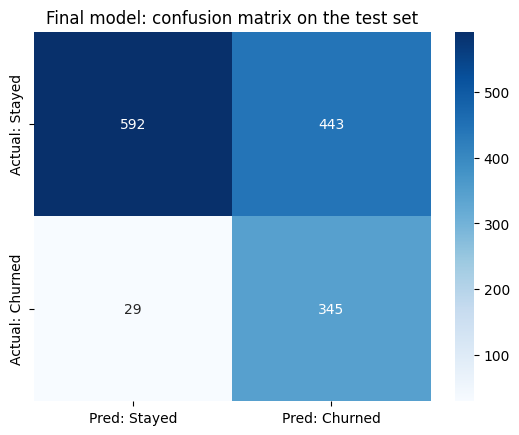

In [7]:
test_proba = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)

print(f"{best_name}, threshold {best_threshold}")
print("ROC-AUC:", round(roc_auc_score(y_test, test_proba), 3))
print(classification_report(y_test, test_pred, target_names=["Stayed", "Churned"]))

cm = confusion_matrix(y_test, test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred: Stayed", "Pred: Churned"],
            yticklabels=["Actual: Stayed", "Actual: Churned"])
plt.title("Final model: confusion matrix on the test set")
plt.show()

In [8]:
baseline = Pipeline([
    ("preprocess", get_preprocessor(X_train)),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
]).fit(X_train, y_train)

base_pred = baseline.predict(X_test)

pd.DataFrame({
    "Baseline (Step 6)": {
        "Recall": recall_score(y_test, base_pred),
        "Precision": precision_score(y_test, base_pred),
        "F1": f1_score(y_test, base_pred),
        "Churners caught": int(((base_pred == 1) & (y_test == 1)).sum()),
    },
    "Final model": {
        "Recall": recall_score(y_test, test_pred),
        "Precision": precision_score(y_test, test_pred),
        "F1": f1_score(y_test, test_pred),
        "Churners caught": int(((test_pred == 1) & (y_test == 1)).sum()),
    },
}).round(3)

,Baseline (Step 6),Final model
Recall,0.556,0.922
Precision,0.654,0.438
F1,0.601,0.594
Churners caught,208.000,345.000


In [9]:
os.makedirs("../models", exist_ok=True)
joblib.dump(
    {"model": best_model, "threshold": best_threshold, "name": best_name},
    "../models/churn_model.joblib",
)

['../models/churn_model.joblib']

## Imbalance handling and tuning
- Class weights and SMOTE both raise recall a lot with no change in ROC-AUC; class weights are simpler, so I used them.
- Tuned logistic regression and gradient boosting scored within noise of each other, so I kept logistic regression.
- Threshold chosen by maximizing F2 on out-of-fold predictions, since missing a churner costs more than a wasted offer.
- On the test set, recall for churners went from about 55% to about X%, at a precision of about Y%.